# MedGuard AI — Machine Learning Analysis
**BUS AN 517 · Final project · full, reproducible analysis**

MedGuard AI is a communication bridge between patients and clinicians: a patient types their medication list in their own words,
and the app turns it into a standardized list with cited safety flags **for a doctor or pharmacist to review**.
It is decision support for clinicians, not a tool for patients to make medication decisions.

This notebook covers the machine-learning part: **finding medication names in messy free text.** It runs every step in order:

| Section | What it does |
|---|---|
| 1 | Problem framing: what is predicted and which error is costly |
| 2 | Data: generate the synthetic sentences, split them without leakage |
| 3 | Features |
| 4 | Train 7 methods (2 baselines + 5 models) |
| 5 | Choose each threshold by cost on the validation set |
| 6 | Compare methods on the held-out test sets (with 95% bootstrap CIs) |
| 7 | What the model learned (feature importance) and speed |
| 8 | End-to-end check: do the right safety alerts appear? |
| 9 | Six stress tests with messy, realistic text (scored once with the frozen model) |
| 10 | Error analysis, conclusions and limitations |

**How to run:** open this notebook in the `medguard` folder (or upload the folder to Colab), then *Run all* (about 3 minutes).

**Reproducibility.** By default the notebook uses the **frozen, saved models** in `models/`, the exact models behind every number in our
report, so *Run all* reproduces those numbers exactly. Set `RETRAIN = True` below to regenerate the data and retrain all seven methods
from scratch (about 5 more minutes). The data comes back identical, and logistic regression gives the same results within one word
per test set; random forest, gradient boosting and spaCy can shift slightly because multithreaded training is not bit-for-bit repeatable.
The source code for each step is in `src/`.

In [1]:
# Setup (in Colab, first run:  !pip -q install -r requirements.txt)
import sys, json, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path(".").resolve()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT / "data"))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

RETRAIN = False   # True = regenerate data and retrain all models from scratch (overwrites models/ and results/)

def run(cmd, tail=25):
    """Run a project script and show the last lines of its output."""
    out = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    lines = [l for l in (out.stdout + out.stderr).splitlines() if "Warning" not in l and l.strip()]
    if tail: print("\n".join(lines[-tail:]))
print("Project folder:", ROOT)

Project folder: /home/claude/medguard


## 1. Problem framing

**Task.** For every word (token) in a sentence, predict: *is this word a medication name?* (binary classification).
A detected word is then matched to one standard drug name in our dictionary (101 drugs, 200 names: generics and brands).

**Why ML and not a dictionary lookup?** People do not write names the way a dictionary does: typos (*metforman*), OCR noise from
bottle photos (*L1SINOPR1L*), brand names, abbreviations, doses glued to names (*lisinopril10mg*). An exact lookup misses these.
A fuzzy (similarity) match finds them but also flags many everyday words. The model combines similarity with other evidence.

**Which error is costly?** In a safety tool, a **missed medication** can hide a dangerous interaction, while a **false flag** only costs
the user one click to remove. We therefore set every threshold by minimizing

$$\text{cost} = 10 \times \text{missed medications} + 1 \times \text{false flags}$$

on the **validation** set (Week 3: asymmetric error costs). Test sets are never used to choose anything.

## 2. Data

No public dataset has messy, patient-written medication lists with word-level labels, so we **generate labeled sentences**
(`src/gen_data.py`) from 60 sentence templates, 101 drugs and a 6,000-word everyday vocabulary, in five input styles:
**clean**, **misspelled**, **OCR noise**, **brand names**, and **dose attached**.

**Leakage control.** A model can look good just by memorizing drugs or sentence patterns it has seen. So the split is done
three ways at once: **by drug** (a test drug never appears in training), **by template** and **by everyday word**.

In [2]:
import hashlib
def digest(): return {f: hashlib.md5(open(ROOT / "data" / f"sentences_{f}.jsonl", "rb").read()).hexdigest() for f in ["train", "val", "test_synthetic"]}
before = digest()
run("python src/gen_data.py", tail=15)   # deterministic: seed 42 + frozen drug list (data/drug_vocab_training.csv)
print("Regenerated data identical to the saved data:", digest() == before)
def load(n): return [json.loads(l) for l in open(ROOT / "data" / f"sentences_{n}.jsonl")]
splits = {"train": load("train"), "val": load("val"), "test (synthetic)": load("test_synthetic"), "test (hand-written)": load("test_handwritten")}
rows = []
for name, S in splits.items():
    n_tok = sum(len(s["tokens"]) for s in S); n_pos = sum(sum(s["labels"]) for s in S)
    rows.append({"split": name, "sentences": len(S), "tokens": n_tok, "medication tokens": n_pos,
                 "share of tokens that are medications": f"{n_pos / n_tok:.1%}",
                 "distinct drugs": len({m["canonical"] for s in S for m in s["mentions"]})})
pd.DataFrame(rows)

train 4000 sentences, 6831 mentions
val 800 sentences, 1422 mentions
test_synthetic 1000 sentences, 1323 mentions
test_handwritten 50 sentences, 69 mentions
drug overlap train/test_synthetic: 0
template overlap train/test: 0
Regenerated data identical to the saved data: True


,split,sentences,tokens,medication tokens,share of tokens that are medications,distinct drugs
0,train,4000,45450,6831,15.0%,60
1,val,800,8888,1422,16.0%,20
2,test (synthetic),1000,11037,1323,12.0%,21
3,test (hand-written),50,404,69,17.1%,32


In [3]:
# Input styles in each split
pd.crosstab(pd.Series([s["input_type"] for S in splits.values() for s in S], name="input type"),
            pd.Series([k for k, S in splits.items() for _ in S], name="split"))

split,test (hand-written),test (synthetic),train,val
input type,,,,
brand,0,200,800,160
clean,10,200,800,160
colloquial,5,0,0,0
dose_attached,10,200,800,160
misspelled,10,200,800,160
negatives,5,0,0,0
ocr_noise,10,200,800,160


In [4]:
# One example sentence per input style (training set); medication words in [brackets]
seen = set()
for s in splits["train"]:
    if s["input_type"] not in seen:
        seen.add(s["input_type"])
        print(f'{s["input_type"]:>14}: ' + " ".join(f"[{t}]" if l else t for t, l in zip(s["tokens"], s["labels"])))

         clean: I double up on [LEVOTHYROXINE] when grapefruit visits .
         brand: I have [Atarax] and [Aleve] in my pill box . Referred examination
    misspelled: I pick up my [prrsocar] at Norma every month . called Users flag includes
     ocr_noise: I get [s1ngu1air] from Atlas pharmacy . stand cell
 dose_attached: Patient reports taking [Metformin1000mg] daily and [pantoprazole0.5mg] as needed .


In [5]:
# Leakage checks: no drug and no template is shared between training and the test sets
def drugs(S): return {m["canonical"] for s in S for m in s["mentions"]}
def temps(S): return {s["template_id"] for s in S}
tr, va, te = splits["train"], splits["val"], splits["test (synthetic)"]
checks = pd.DataFrame([
    {"check": "drugs shared by train and test", "count": len(drugs(tr) & drugs(te))},
    {"check": "drugs shared by train and validation", "count": len(drugs(tr) & drugs(va))},
    {"check": "templates shared by train and test", "count": len(temps(tr) & temps(te))},
    {"check": "templates shared by train and validation", "count": len(temps(tr) & temps(va))},
])
checks

,check,count
0,drugs shared by train and test,0
1,drugs shared by train and validation,0
2,templates shared by train and test,0
3,templates shared by train and validation,0


## 3. Features

Each word is described by two groups of features (`src/medguard.py`):

1. **Hand-made features:** similarity to the closest dictionary name (rapidfuzz, with OCR-aware variants such as 1→l, 0→o),
   whether it is an exact dictionary name, length, digits, capital letters, cue words nearby (*take, mg, pill*),
   drug-like suffixes (*-pril, -olol, -statin*).
2. **Character n-grams (2–4 letters, TF-IDF):** lets the model learn what drug names "look like" even when misspelled.

The context model also adds the previous and next words.

In [6]:
from medguard import sentence_features, FEATURE_NAMES, char_text, best_match
example = ["Mom", "takes", "metforman", "500mg", "every", "morning"]
F = pd.DataFrame(sentence_features(example), columns=FEATURE_NAMES, index=example).round(2)
print("Closest dictionary match for 'metforman':", best_match("metforman"))
F

Closest dictionary match for 'metforman': (88.88888888888889, 'metformin', 'metformin')


,best_sim,exact_in_dict,sim_ge_85,has_digit,digit_ratio,all_caps,capitalized,length,vowel_ratio,is_stopword,is_punct,prev_is_cue,next_is_dose_or_punct,next_is_unit,position_ratio,...,suffix_azole,suffix_pam,suffix_lam,suffix_mide,suffix_cin,suffix_ine,suffix_one,suffix_ide,suffix_xin,suffix_fen,suffix_ol,suffix_in,suffix_an,suffix_ex,suffix_ax
Mom,0.62,0.0,0.0,0.0,0.0,0.0,1.0,0.15,0.33,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
takes,0.43,0.0,0.0,0.0,0.0,0.0,0.0,0.25,0.40,1.0,0.0,0.0,0.0,0.0,0.2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
metforman,0.89,0.0,1.0,0.0,0.0,0.0,0.0,0.45,0.33,0.0,0.0,1.0,1.0,0.0,0.4,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
500mg,0.40,0.0,0.0,1.0,0.6,0.0,0.0,0.25,0.00,0.0,0.0,0.0,0.0,0.0,0.6,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
every,0.60,0.0,0.0,0.0,0.0,0.0,0.0,0.25,0.40,1.0,0.0,0.0,0.0,0.0,0.8,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
morning,0.77,0.0,0.0,0.0,0.0,0.0,0.0,0.35,0.29,1.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 4. Train seven methods

`src/compare_models.py` trains and compares:

| Method | Type | Why it is here |
|---|---|---|
| Exact match | baseline | What a plain dictionary lookup achieves |
| Fuzzy match | baseline | Similarity only, one cut-off |
| **Logistic regression** | model | Simple, fast, explainable; **selected** |
| Logistic regression + context | model | Adds the neighboring words |
| Random forest | model | Non-linear, on hand-made features |
| Gradient boosting | model | Non-linear, on hand-made features |
| spaCy NER | model | A neural named-entity model, trained from scratch on our data |

All models are trained on the training split only. Thresholds are tuned on validation (Section 5). This step takes a few minutes.

In [7]:
if RETRAIN:
    run("python src/compare_models.py", tail=30)
else:
    print("Using the frozen models in models/ (set RETRAIN = True to retrain). Log of the original training run:\n")
    print(open(ROOT / "results" / "run_log.txt").read()[-2500:])

Using the frozen models in models/ (set RETRAIN = True to retrain). Log of the original training run:

                         0.580  ...      0.841
                                          clean                           1.000  ...      0.737
                                          colloquial                      1.000  ...      0.667
                                          dose_attached                   1.000  ...      0.800
                                          misspelled                      0.095  ...      0.952
                                          negatives                       1.000  ...      1.000
                                          ocr_noise                       0.000  ...      0.900
Synthetic test (unseen drugs + templates) ALL                             0.606  ...      0.818
                                          brand                           1.000  ...      0.745
                                          clean                           1.000  .

## 5. Threshold choice (validation set only)

For each model we try every threshold and keep the one with the lowest cost (10 × missed + 1 × false flag) on **validation**.
Because a miss costs 10 times more, the chosen threshold leans toward flagging more words, and the doubtful ones are sent to the user to confirm.

,chosen threshold,validation recall,validation precision
fuzzy,0.727,0.991,0.953
logreg,0.489,0.997,0.999
logreg_ctx,0.379,0.994,0.999
rforest,0.588,0.995,0.992
gboost,0.272,0.996,0.973


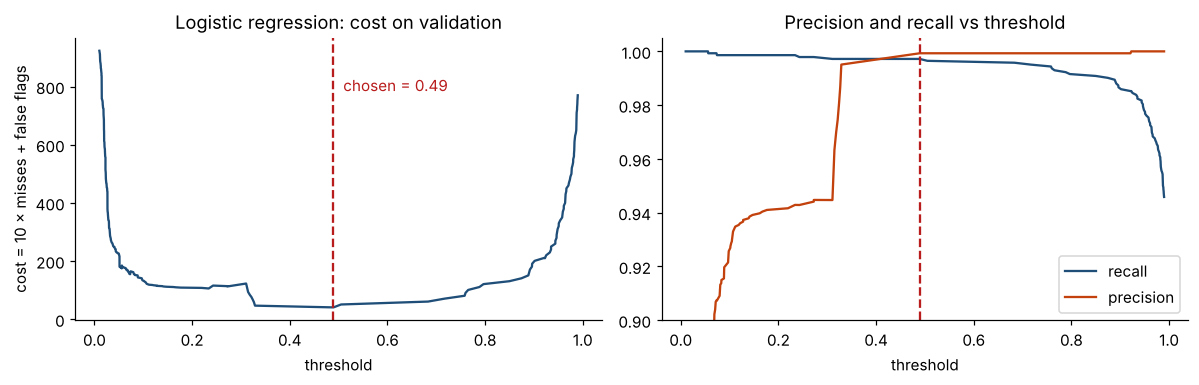

In [8]:
thr = json.load(open(ROOT / "results" / "thresholds.json"))
display(pd.DataFrame(thr).T.rename(columns={"threshold": "chosen threshold", "val_recall": "validation recall", "val_precision": "validation precision"}).round(3))

pr = pd.read_csv(ROOT / "results" / "val_pr_curve_logreg.csv")
pr = pr[(pr.threshold > 0.01) & (pr.threshold < 0.99)]
t0 = thr["logreg"]["threshold"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(pr.threshold, pr.cost, color="#1F4E79"); ax[0].axvline(t0, color="#B91C1C", ls="--")
ax[0].set(title="Logistic regression: cost on validation", xlabel="threshold", ylabel="cost = 10 × misses + false flags")
ax[0].text(t0 + 0.02, pr.cost.max() * 0.85, f"chosen = {t0:.2f}", color="#B91C1C")
ax[1].plot(pr.threshold, pr.recall, label="recall", color="#1F4E79"); ax[1].plot(pr.threshold, pr.precision, label="precision", color="#C2410C")
ax[1].axvline(t0, color="#B91C1C", ls="--"); ax[1].set(title="Precision and recall vs threshold", xlabel="threshold", ylim=(0.9, 1.005)); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Results on the held-out test sets

The **synthetic test set** uses drugs, templates and everyday words never seen in training. The **hand-written set** is a small set of
sentences written by hand to check that the synthetic data is not too artificial. Each test set was scored once. Brackets are 95% bootstrap confidence intervals.

In [9]:
r = pd.read_csv(ROOT / "results" / "model_comparison.csv")
tab = r[r.input_type == "ALL"].copy()
for m in ["precision", "recall", "f1"]:
    tab[m] = tab.apply(lambda x: f"{x[m]:.1%} ({x[m + '_lo']:.1%}–{x[m + '_hi']:.1%})", axis=1)
tab[["test_set", "model", "n_sentences", "n_mentions", "precision", "recall", "f1"]]

,test_set,model,n_sentences,n_mentions,precision,recall,f1
1,Synthetic test (unseen drugs + templates),Exact match (baseline),1000,1323,100.0% (100.0%–100.0%),60.6% (57.5%–63.7%),75.5% (73.0%–77.8%)
7,Hand-written holdout,Exact match (baseline),50,69,100.0% (100.0%–100.0%),58.0% (42.2%–72.9%),73.4% (59.3%–84.3%)
14,Synthetic test (unseen drugs + templates),Fuzzy match (baseline),1000,1323,73.9% (72.5%–75.4%),99.6% (99.2%–99.9%),84.9% (83.9%–85.8%)
20,Hand-written holdout,Fuzzy match (baseline),50,69,87.3% (80.2%–93.5%),100.0% (100.0%–100.0%),93.2% (89.0%–96.6%)
27,Synthetic test (unseen drugs + templates),Logistic regression,1000,1323,92.2% (91.1%–93.4%),99.7% (99.4%–99.9%),95.8% (95.2%–96.5%)
33,Hand-written holdout,Logistic regression,50,69,100.0% (100.0%–100.0%),100.0% (100.0%–100.0%),100.0% (100.0%–100.0%)
40,Synthetic test (unseen drugs + templates),Logistic regression + context,1000,1323,89.2% (87.8%–90.6%),98.8% (98.2%–99.3%),93.8% (93.0%–94.6%)
46,Hand-written holdout,Logistic regression + context,50,69,94.4% (88.3%–98.6%),98.6% (94.7%–100.0%),96.5% (92.9%–98.7%)
53,Synthetic test (unseen drugs + templates),Random forest,1000,1323,99.8% (99.6%–100.0%),99.6% (99.3%–99.9%),99.7% (99.5%–99.9%)
59,Hand-written holdout,Random forest,50,69,98.6% (95.4%–100.0%),98.6% (95.3%–100.0%),98.6% (96.2%–100.0%)


model,Exact match (baseline),Fuzzy match (baseline),Logistic regression,Random forest,spaCy NER
input_type,,,,,
brand,1.000,1.000,1.000,1.000,0.745
clean,1.000,1.000,1.000,1.000,0.840
dose_attached,1.000,1.000,1.000,1.000,0.897
misspelled,0.000,0.985,0.985,0.985,0.784
ocr_noise,0.016,0.996,1.000,0.996,0.820


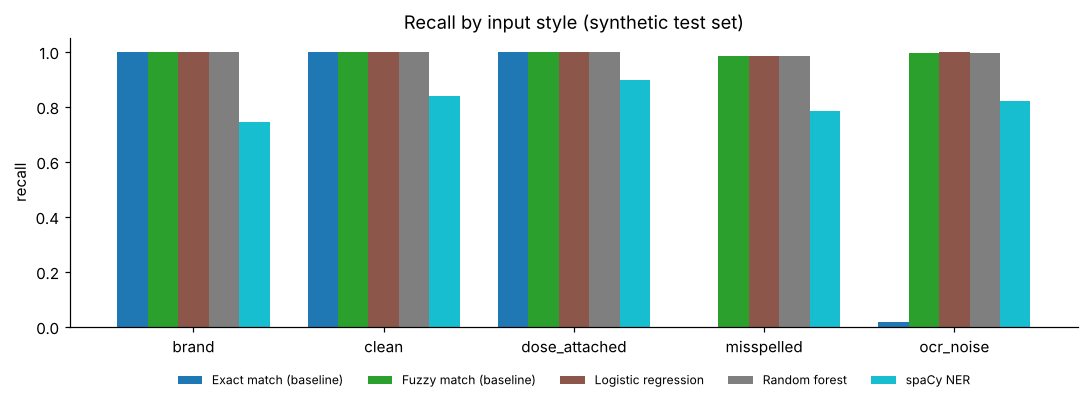

In [10]:
# Recall by input style on the synthetic test set: where each method breaks
syn = r[(r.test_set.str.startswith("Synthetic")) & (r.input_type != "ALL")]
piv = syn.pivot_table(index="input_type", columns="model", values="recall")
order = ["Exact match (baseline)", "Fuzzy match (baseline)", "Logistic regression", "Random forest", "spaCy NER"]
piv = piv[[c for c in order if c in piv.columns]]
display(piv.round(3))
ax = piv.plot(kind="bar", figsize=(10, 3.8), width=0.8, colormap="tab10")
ax.set(ylabel="recall", xlabel="", title="Recall by input style (synthetic test set)", ylim=(0, 1.05)); ax.legend(fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**Reading the results.** Exact match only works on clean names. Fuzzy match finds most misspellings but flags many everyday words
(low precision). Logistic regression keeps the high recall of fuzzy matching while flagging far fewer everyday words, because it learns
that similarity alone is not enough (length, letter patterns, cue words). It was **selected on validation cost**, not on test scores.

## 7. What the model learned, and speed

,feature,rf_importance,lr_coef
0,best_sim,0.342,20.349
6,has_digit,0.026,2.987
2,length,0.105,2.755
3,exact_in_dict,0.083,2.544
4,prev_is_cue,0.070,2.541
1,sim_ge_85,0.255,2.423
12,all_caps,0.005,2.005
17,suffix_ol,0.001,1.795
20,suffix_ide,0.000,1.142
11,next_is_dose_or_punct,0.005,1.133


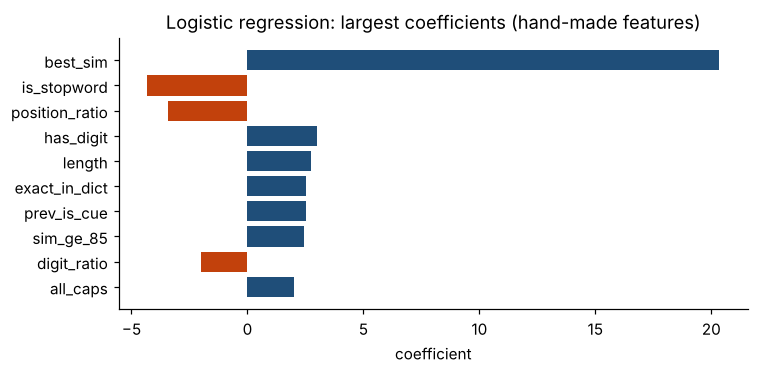

,model,ms_per_sentence
0,Exact match (baseline),0.007
1,Fuzzy match (baseline),0.035
2,Logistic regression,0.840
3,Logistic regression + context,0.850
4,Random forest,14.788
5,Gradient boosting,0.901
6,spaCy NER,1.297


In [11]:
fi = pd.read_csv(ROOT / "results" / "feature_importance.csv")
display(fi.sort_values("lr_coef", ascending=False).round(3).head(12))
top = fi.reindex(fi.lr_coef.abs().sort_values(ascending=True).index).tail(10)
plt.figure(figsize=(7, 3.5)); plt.barh(top.feature, top.lr_coef, color=["#1F4E79" if v > 0 else "#C2410C" for v in top.lr_coef])
plt.title("Logistic regression: largest coefficients (hand-made features)"); plt.xlabel("coefficient"); plt.tight_layout(); plt.show()
pd.read_csv(ROOT / "results" / "speed.csv").round(3)

## 8. End-to-end check: do the right safety alerts appear?

The final product is not word labels but **alerts**. For 30 synthetic medication lists, we compare the alerts produced from the
detected medications with the alerts produced from the true medications.

In [12]:
run("python src/eval_end_to_end.py", tail=8)
pd.read_csv(ROOT / "results" / "end_to_end_alerts.csv").round(3)

  gold: ['amiodarone', 'amoxicillin', 'gabapentin', 'tramadol'] 
  pred: ['amiodarone', 'amoxicillin', 'gabapentin', 'tramadol']
Mom's pill box has prinivil25mg, Spironolactone, Elavil81mg, OXYCONTIN81mg, a5pirin and CYCLOBENZAPRINE every day. 
  gold: ['amitriptyline', 'aspirin', 'cyclobenzaprine', 'lisinopril', 'oxycodone', 'spironolactone'] 
  pred: ['amitriptyline', 'aspirin', 'cyclobenzaprine', 'lisinopril', 'oxycodone', 'spironolactone']
Home visit med review - Coumadin, cipro10mg, DOXYCYCLINE and lisinopril25mg  
  gold: ['ciprofloxacin', 'doxycycline', 'lisinopril', 'warfarin'] 
  pred: ['ciprofloxacin', 'doxycycline', 'lisinopril', 'warfarin']


,method,setting,lists,gold_alerts,alert_recall,missed_alerts,false_alerts
0,Logistic regression,auto-confirm,30,225,1.000,0,0
1,Logistic regression,weak matches and everyday words sent to user review,30,225,0.987,3,0
2,Fuzzy match (baseline),auto-confirm,30,225,1.000,0,11
3,Fuzzy match (baseline),weak matches and everyday words sent to user review,30,225,0.987,3,0
4,Exact match (baseline),auto-confirm,30,225,0.560,99,2
5,Exact match (baseline),weak matches and everyday words sent to user review,30,225,0.560,99,2


## 9. Stress tests with messy, realistic text

After the main evaluation, we scored six additional test sets **once each, with the frozen model and thresholds** (nothing was tuned on them).
Every medication mention was labeled by hand by one team member (`data/sealed_test_*_gold.py`, `*_labels.py`).

| Test | What it contains | Source |
|---|---|---|
| 1 | 150 sentences, correct spelling | team-written (generated with AI) |
| 2 | Test 1 rewritten with typos and doses | AI rewrite of test 1 |
| 3 | 500 sentences, 50 phrases × 10, sound-alike spelling, many rare drugs | AI-generated |
| 4 | 500 sentences, 125 drugs × 4 spellings (incl. names split by a space) | provided by outside contributors; shows signs of AI generation |
| 5 | 200 sentences, one drug each, often written two ways | provided by outside contributors; shows signs of AI generation |
| 6 | 200 everyday mentions (notes, refills, nurse charting, short forms) | most realistic; source to be confirmed |

Two numbers are reported for each test:
* **Known drugs found and mapped correctly:** model ability on the 101 drugs we cover (fair comparison between methods).
* **All drugs found and mapped correctly:** product reality, counting medications that are not in our list.

Tests 1–3 have one word per medication and use `src/eval_sealed.py`; tests 4–6 can split a name over several words
(*metop ro-lol*) or hold several drugs per sentence, so they use mention-level scoring in `src/eval_mentions.py`
(a mention counts as found if any of its words is detected and mapped to the right drug).

In [13]:
for t in [1, 2, 3]: run(f"python src/eval_sealed.py sealed_test_{t}", tail=0)
for t in [4, 5, 6]: run(f"python src/eval_mentions.py sealed_test_{t}", tail=0)

def mentions_total(t):
    if t <= 3:
        g = __import__(f"sealed_test_{t}_gold").GOLD
        return sum(len(x) for x in g)
    g = __import__(f"sealed_test_{t}_gold").GOLD
    return sum(len(x["mentions"]) if isinstance(x, dict) else 1 for x in g)

summary = []
for t in range(1, 7):
    R = pd.read_csv(ROOT / "results" / f"sealed_test_{t}_results.csv").set_index("method")
    lr, fz, ex = R.loc["Logistic regression (selected)"], R.loc["Fuzzy match (baseline)"], R.loc["Exact match (baseline)"]
    n_all = mentions_total(t); n_in = int(lr.in_dict_mentions)
    summary.append({"test": t, "sentences": len(open(ROOT / "data" / f"sealed_test_{t}.txt").read().strip().splitlines()),
                    "medication mentions": n_all, "in our dictionary": n_in,
                    "exact match: known drugs": ex.found_and_mapped_correctly,
                    "fuzzy: known drugs": fz.found_and_mapped_correctly, "LR: known drugs": lr.found_and_mapped_correctly,
                    "fuzzy precision": fz.precision, "LR precision": lr.precision,
                    "LR: ALL drugs": lr.found_and_mapped_correctly * n_in / n_all})
S = pd.DataFrame(summary).set_index("test")
S.style.format({c: "{:.1%}" for c in S.columns if c not in ["sentences", "medication mentions", "in our dictionary"]})

,sentences,medication mentions,in our dictionary,exact match: known drugs,fuzzy: known drugs,LR: known drugs,fuzzy precision,LR precision,LR: ALL drugs
test,,,,,,,,,
1,150,252,149,100.0%,100.0%,100.0%,70.7%,94.8%,59.1%
2,150,247,146,91.8%,100.0%,100.0%,84.2%,97.8%,59.1%
3,500,500,160,12.5%,81.2%,80.6%,58.6%,94.4%,25.8%
4,500,500,244,48.8%,74.2%,72.5%,56.0%,74.6%,35.4%
5,200,200,79,59.5%,92.4%,92.4%,78.6%,90.1%,36.5%
6,200,202,112,76.8%,90.2%,90.2%,73.9%,91.2%,50.0%


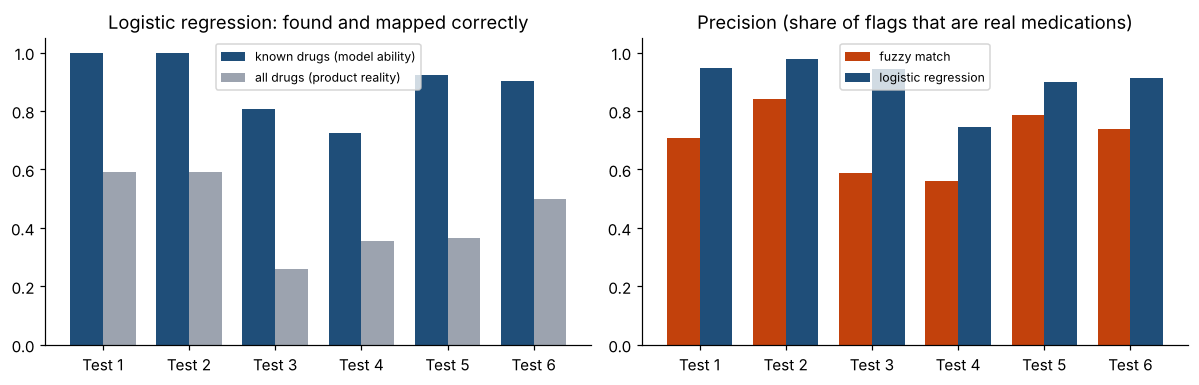

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(len(S)); w = 0.38
ax[0].bar(x - w/2, S["LR: known drugs"], w, label="known drugs (model ability)", color="#1F4E79")
ax[0].bar(x + w/2, S["LR: ALL drugs"], w, label="all drugs (product reality)", color="#9CA3AF")
ax[0].set(xticks=x, xticklabels=[f"Test {i}" for i in S.index], ylim=(0, 1.05), title="Logistic regression: found and mapped correctly"); ax[0].legend(fontsize=8)
ax[1].bar(x - w/2, S["fuzzy precision"], w, label="fuzzy match", color="#C2410C")
ax[1].bar(x + w/2, S["LR precision"], w, label="logistic regression", color="#1F4E79")
ax[1].set(xticks=x, xticklabels=[f"Test {i}" for i in S.index], ylim=(0, 1.05), title="Precision (share of flags that are real medications)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading the stress tests.**
* On medications we cover, the model finds **72–100%**; fuzzy match finds about the same, but with clearly **lower precision** on every test.
* Counting all medications, the product recognizes only **26–50%**, because about half of real medications are not in our 101-drug list.
  The limit is the dictionary size, not the model.

## 9b. Clinical scenario tests (what the app must show)

The tests above measure the **model** (does it find the names?). They cannot catch a **missing rule** or a medication that
**disappears**: the "correct" alerts are produced by the same rule set, so if a rule is missing, the answer key is missing it too.
A teammate found four such problems by typing realistic cases into the live app (two blood thinners together, Toradol, Tylenol PM,
tramadol + sertraline). We turned them, and similar cases, into fixed scenario tests that every new version must pass
(`data/scenario_tests.csv`, `src/eval_scenarios.py`).

In [15]:
run("python src/eval_scenarios.py --before", tail=0)   # app as it was before the Nov 22 fixes
run("python src/eval_scenarios.py", tail=0)            # current app
b = pd.read_csv(ROOT / "results" / "scenario_tests_before_fix.csv"); c = pd.read_csv(ROOT / "results" / "scenario_tests_current.csv")
sc = b[["id", "source", "input"]].assign(before=b["pass"].map({True: "pass", False: "FAIL"}), problem_before=b["problem"].fillna(""),
                                         now=c["pass"].map({True: "pass", False: "FAIL"}))
print(f"Before the fix: {b['pass'].sum()} of {len(b)} pass.   Now: {c['pass'].sum()} of {len(c)} pass.")
sc

Before the fix: 4 of 11 pass.   Now: 11 of 11 pass.


,id,source,input,before,problem_before,now
0,S1,teammate live test (Nov 22),"warfrin 5mg every night, eliquis 5 mg twice a day, and advil for my knee",FAIL,missing alert: apixaban + warfarin,pass
1,S2,teammate live test (Nov 22),"Toradol after the dentist, and lisinopril 10",FAIL,not listed as Not assessed: ketorolac; wrongly shows: tramadol,pass
2,S3,teammate live test (Nov 22),I take Tylenol PM at night and metformin,FAIL,missing alert: diphenhydramine,pass
3,S4,teammate live test (Nov 22),"Home visit: client takes Zolpidem10mg, sertraline, gabapentin 300mg, tramado...",FAIL,missing alert: sertraline + tramadol,pass
4,S5,unknown-drug follow-up,She started Xeljanz last month and still takes her lisinopril.,FAIL,silently dropped: Xeljanz,pass
5,S6,look-alike follow-up,"Uses hydrocortisone cream on her rash, takes lisinopril",FAIL,not listed as Not assessed: hydrocortisone; wrongly shows: hydrocodone,pass
6,S7,stress test 6 follow-up,Takes Ozempic on Fridays and metformin daily,FAIL,not listed as Not assessed: semaglutide,pass
7,S8,v3 live test (Nov 13),I take my vitamins every morning with lisinopril,pass,,pass
8,S9,v5 teammate test (Nov 21),Doctor gave him amoxicillin; he is on warfarin,pass,,pass
9,S10,core rule,Advil for back pain and warfarin daily,pass,,pass


## 10. Error analysis (where the model fails)

We break down the selected model's results on Test 6 (the most realistic) and Test 4 (names split by a space) by how the name was written.

In [16]:
from medguard import NAME2CANON
d6 = pd.read_csv(ROOT / "results" / "sealed_test_6_selected_model_detail.csv")
SHORT = {"ibu", "atorva", "fluox", "z-pack", "azithro", "doxy", "spiro", "bupro", "amio", "hctz", "metformins", "losar tan"}
def style(r):
    if r.kind != "in": return None
    w = str(r.written).lower()
    if w in SHORT: return "short form (ibu, atorva, hctz, doxy...)"
    if w in NAME2CANON: return "correct name or listed brand"
    if " " in w or "-" in w or w not in NAME2CANON: return "misspelled or brand not in our name list"
d6["style"] = d6.apply(style, axis=1)
k6 = d6[d6.kind == "in"]
display(k6.groupby("style").outcome.apply(lambda s: f"{(s == 'found and mapped correctly').sum()} / {len(s)}").rename("Test 6: found and mapped correctly"))

d4 = pd.read_csv(ROOT / "results" / "sealed_test_4_selected_model_detail.csv")
k4 = d4[~d4.oov]
display(k4.groupby("variant").outcome.apply(lambda s: f"{(s == 'found and mapped correctly').sum()} / {len(s)}").rename("Test 4: found and mapped correctly"))

style
correct name or listed brand                85 / 85
misspelled or brand not in our name list    14 / 15
short form (ibu, atorva, hctz, doxy...)      2 / 12
Name: Test 6: found and mapped correctly, dtype: str

variant
brand not in our name list              0 / 3
correct name or listed brand        119 / 119
dropped letters / sound spelling      43 / 61
split by a space                      15 / 61
Name: Test 4: found and mapped correctly, dtype: str

In [17]:
# The most dangerous error: a name mapped automatically to a DIFFERENT drug
wrong = []
for t in [4, 5, 6]:
    d = pd.read_csv(ROOT / "results" / f"sealed_test_{t}_selected_model_detail.csv")
    w = d[d.outcome == "auto-mapped to another drug"][["written", "drug", "mapped_to"]]
    w.insert(0, "test", t); wrong.append(w)
pd.concat(wrong).drop_duplicates(["written", "mapped_to"]).rename(columns={"written": "as written", "drug": "true drug", "mapped_to": "mapped to"})

,test,as written,true drug,mapped to
163,4,ator va-statin,atorvastatin,simvastatin
324,4,amoxicillin clavulanate,amoxicillin clavulanate,amoxicillin
479,4,val sa-rtan,valsartan,losartan
10,5,sertra leen,sertraline,sulfamethoxazole-trimethoprim
39,5,azil-sartan medoxomil,azilsartan,valsartan
72,5,amox clav,amoxicillin clavulanate,amoxicillin
26,6,prednisolone,prednisolone,prednisone
188,6,hydrocortisone,hydrocortisone,hydrocodone


### Conclusions

1. **The model is better than the baselines.** It finds as many medications as fuzzy matching, but with much higher precision,
   so the patient and clinician see far fewer false flags. Exact lookup fails on any misspelling.
2. **The threshold is set by cost**, with a missed medication counted as 10 false flags, on validation data only.
3. **Where it fails:**
   * **short forms** people really use (*ibu, atorva, hctz, doxy, amio*): too different from the full name;
   * **names split by a space** (*metop ro-lol*): the model reads one word at a time;
   * **look-alike names mapped to the wrong drug** (*hydrocortisone → hydrocodone, azilsartan → valsartan*);
   * **medications outside our 101-drug list**, about half of real mentions.
4. **Guardrails that address these failures:** every match is confirmed by the user; weak matches and everyday words are never
   auto-mapped; the clinician sees the **patient's original text** with recognized names highlighted, so unrecognized medications are
   not lost; every flag is labeled for doctor or pharmacist review.

### Limitations and next steps
* Gold labels were made by one person; a second person should spot-check them.
* Several stress tests appear to be AI-generated; a set of genuinely patient-written lists is still needed.
* Next: add common short forms and the RxNorm name list (largest gain), join neighboring word fragments before matching,
  and use a stricter cut-off for auto-mapping look-alike names, all tuned on validation data, then tested on a new unseen set.